# 🎥 30-Question Movies Dataset Challenge (Step-by-Step)
This notebook goes through all 30 questions from the analytics challenge, providing step-by-step code, logic explanations, and beautiful visualisations using pandas, matplotlib, and seaborn.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style='darkgrid', palette='muted')
import warnings
warnings.filterwarnings('ignore')


### Q1. How do we load the dataset and see the first 5 rows?


In [2]:
df = pd.read_csv('movies.csv')
display(df.head())


,id,name,year,rating,certificate,duration,genre,votes,gross_income,directors_id,directors_name,stars_id,stars_name,description
0,tt0068646,The Godfather,1972,9.2,R,175 min,"Crime, Drama",1798749,"134,966,411",nm0000338,Francis Ford Coppola,"nm0000008,nm0000199,nm0001001,nm0000473","Marlon Brando,Al Pacino,James Caan,Diane Keaton",The aging patriarch of an organized crime dyna...
1,tt5113044,Minions: The Rise of Gru,2022,7.3,PG,87 min,"Animation, Adventure, Comedy","1,220","134,966,411","nm0049633,nm1556070,nm3646390","Kyle Balda,Brad Ableson,Jonathan del Val","nm0136797,nm1853544,nm0000273,nm0378245","Steve Carell,Pierre Coffin,Alan Arkin,Taraji P...",The untold story of one twelve-year-old's drea...
2,tt7657566,Death on the Nile,2022,6.3,PG-13,127 min,"Crime, Drama, Mystery","121,063","134,966,411",nm0000110,Kenneth Branagh,"nm5290643,nm0000906,nm0000110,nm1258970","Tom Bateman,Annette Bening,Kenneth Branagh,Rus...","While on vacation on the Nile, Hercule Poirot ..."
3,tt8115900,The Bad Guys,2022,6.9,PG,100 min,"Animation, Adventure, Comedy","23,090","134,966,411",nm2010048,Pierre Perifel,"nm0005377,nm0549505,nm5377144,nm0732497","Sam Rockwell,Marc Maron,Awkwafina,Craig Robinson",Several reformed yet misunderstood criminal an...
4,tt10809742,Collision,2022,3.8,TV-MA,99 min,"Crime, Drama, Thriller",656,"134,966,411",nm1926494,Fabien Martorell,"nm1339181,nm0456810,nm12651040,nm7357127","Tessa Jubber,Langley Kirkwood,Zoey Sneedon,Bon...",Freedom always comes at a price.


### Q2. What are the data types of each column?


In [3]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19808 entries, 0 to 19807
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              19808 non-null  object 
 1   name            19808 non-null  object 
 2   year            19808 non-null  int64  
 3   rating          19808 non-null  float64
 4   certificate     19808 non-null  object 
 5   duration        19808 non-null  object 
 6   genre           19808 non-null  object 
 7   votes           19808 non-null  object 
 8   gross_income    19808 non-null  object 
 9   directors_id    19808 non-null  object 
 10  directors_name  19808 non-null  object 
 11  stars_id        19808 non-null  object 
 12  stars_name      19808 non-null  object 
 13  description     19808 non-null  object 
dtypes: float64(1), int64(1), object(12)
memory usage: 2.1+ MB
None


### Q3. How do we clean the 'duration' column (e.g., '175 min' -> 175)?
*Explanation:* Duration is currently text (object). We remove the word ' min' and convert the result to numbers.


In [4]:
df['duration_num'] = df['duration'].astype(str).str.replace(' min', '', regex=False)
df['duration_num'] = pd.to_numeric(df['duration_num'], errors='coerce')
print(df[['duration', 'duration_num']].head())


  duration  duration_num
0  175 min         175.0
1   87 min          87.0
2  127 min         127.0
3  100 min         100.0
4   99 min          99.0


### Q4. How do we clean the 'gross' column and 'votes' column?
*Explanation:* Numbers over a thousand have commas (e.g., 1,220). We must replace the comma with nothing before converting to numeric.


In [5]:
df['gross_income_num'] = df['gross_income'].astype(str).str.replace(',', '', regex=False)
df['gross_income_num'] = pd.to_numeric(df['gross_income_num'], errors='coerce')

df['votes_num'] = df['votes'].astype(str).str.replace(',', '', regex=False)
df['votes_num'] = pd.to_numeric(df['votes_num'], errors='coerce')

print(df[['gross_income', 'gross_income_num', 'votes', 'votes_num']].head())


  gross_income  gross_income_num    votes  votes_num
0  134,966,411       134966411.0  1798749    1798749
1  134,966,411       134966411.0    1,220       1220
2  134,966,411       134966411.0  121,063     121063
3  134,966,411       134966411.0   23,090      23090
4  134,966,411       134966411.0      656        656


### Q5. How many missing values are in each column?


In [6]:
print(df.isnull().sum())


id                   0
name                 0
year                 0
rating               0
certificate          0
duration             0
genre                0
votes                0
gross_income         0
directors_id         0
directors_name       0
stars_id             0
stars_name           0
description          0
duration_num         1
gross_income_num    19
votes_num            0
dtype: int64


### Q6. How do we handle missing ratings?
*Explanation:* Even though our dataset has 0 missing values, if it did, we would either drop them using `dropna()` or fill them using the average rating with `fillna()`.


In [7]:
# Example of how we WOULD handle it if there were missing values
df_clean = df.dropna(subset=['rating'])
print("Rows after dropping missing ratings:", len(df_clean))


Rows after dropping missing ratings: 19808


### Q7. What is the distribution of movie ratings?


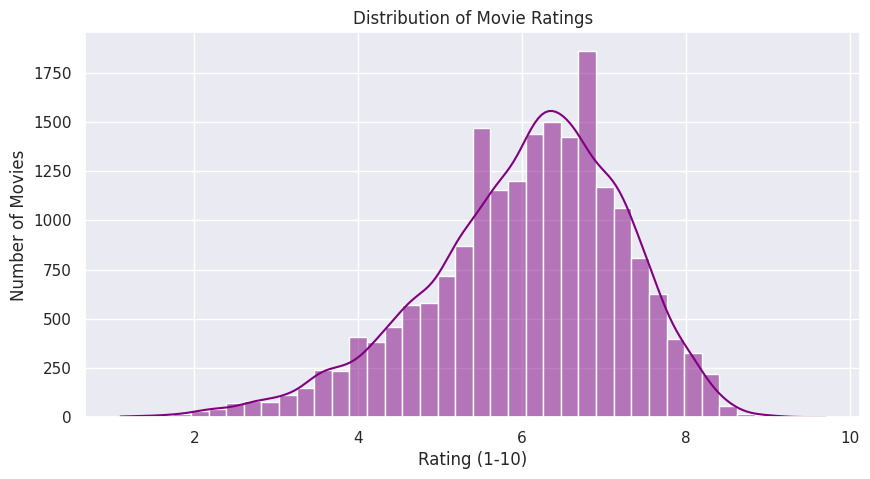

In [8]:
plt.figure(figsize=(10, 5))
sns.histplot(df['rating'], bins=40, kde=True, color='purple')
plt.title('Distribution of Movie Ratings')
plt.xlabel('Rating (1-10)')
plt.ylabel('Number of Movies')
plt.show()


### Q8. Which are the top 5 most common genres?
*Explanation:* Because multiple genres are grouped together (e.g. 'Action, Crime'), we will explode the genres exactly as we learned to get the true counts for individual genres!


In [9]:
df_exploded = df.assign(genre_split=df['genre'].str.split(', ')).explode('genre_split')
top_genres = df_exploded['genre_split'].value_counts().head(5)
top_genres


,count
genre_split,
Drama,9655
Action,5290
Crime,5244
Comedy,4641
Thriller,4231


### Q9. What are the unique certificates in the dataset?


In [10]:
unique_certs = df['certificate'].unique()
print(unique_certs)


['R' 'PG' 'PG-13' 'TV-MA' 'Not Rated' 'Approved' 'TV-14' 'NC-17' 'Unrated'
 'G' 'Passed' 'GP' 'X' 'M/PG' 'M' 'TV-PG' 'TV-G' '12' 'TV-13' 'TV-Y7-FV'
 'MA-17' 'AO' '18' 'R-15' 'R-12' 'R-18' 'PG-12' '6+' 'TV-Y7' 'TV-Y'
 'MA-13']


In [11]:
num_unique_certs = df['certificate'].nunique()
print(num_unique_certs)

31


### Q10. How many movies were released each year?


In [12]:
movies_per_year = df['year'].value_counts().sort_index()

movies_per_year

,count
year,
1894,1
1898,1
1902,2
1903,1
1913,3
...,...
2018,736
2019,657
2020,467


### Q11. Which directors have directed the most movies?


In [13]:
top_directors = df['directors_name'].value_counts().head(5)

top_directors

,count
directors_name,
Alfred Hitchcock,38
Clint Eastwood,36
Henry Hathaway,29
Steven Spielberg,29
Raoul Walsh,27


### Q12. Do longer movies get better ratings?


In [14]:
corr = df['duration_num'].corr(df['rating'])
print(f"Correlation coefficient: {corr:.2f} (Weak Positive Correlation)")


Correlation coefficient: 0.25 (Weak Positive Correlation)


### Q13. Which genre has the highest average rating?
*Explanation:* Using our safely exploded dataframe so we get individual genres!


In [15]:
top_rated_genres = df_exploded.groupby('genre_split')['rating'].mean().sort_values(ascending=False).head(5)
print("Top 5 Genres by Average Rating:\n", top_rated_genres)


Top 5 Genres by Average Rating:
 genre_split
Documentary    7.185514
Reality-TV     7.100000
Short          7.063351
Biography      6.860367
Film-Noir      6.821493
Name: rating, dtype: float64


### Q14. Which genre makes the most money (Avg Gross)?


In [16]:
top_gross_genres = df_exploded.groupby('genre_split')['gross_income_num'].mean().sort_values(ascending=False).head(5)
print("Top 5 Genres by Average Gross Income:\n", top_gross_genres)


Top 5 Genres by Average Gross Income:
 genre_split
Animation    4.516674e+07
Adventure    4.208013e+07
Sci-Fi       3.363653e+07
Fantasy      2.806378e+07
Family       2.800047e+07
Name: gross_income_num, dtype: float64


### Q15. Who is the highest-grossing director of all time (in this dataset)?


In [17]:
director_gross = df.groupby('directors_name')['gross_income_num'].sum().sort_values(ascending=False).head(5)

director_gross

,gross_income_num
directors_name,
Steven Spielberg,4.247700e+09
Michael Bay,2.703051e+09
"Anthony Russo,Joe Russo",2.262877e+09
J.J. Abrams,2.199407e+09
Peter Jackson,2.156934e+09


### Q16. How does Certificate affect Gross Income?


In [18]:
plt.figure(figsize=(12, 6))
top_certs = df['certificate'].value_counts().head(6).index
filtered_certs = df[df['certificate'].isin(top_certs)]
filtered_certs

,id,name,year,rating,certificate,duration,genre,votes,gross_income,directors_id,directors_name,stars_id,stars_name,description,duration_num,gross_income_num,votes_num
0,tt0068646,The Godfather,1972,9.2,R,175 min,"Crime, Drama",1798749,"134,966,411",nm0000338,Francis Ford Coppola,"nm0000008,nm0000199,nm0001001,nm0000473","Marlon Brando,Al Pacino,James Caan,Diane Keaton",The aging patriarch of an organized crime dyna...,175.0,134966411.0,1798749
1,tt5113044,Minions: The Rise of Gru,2022,7.3,PG,87 min,"Animation, Adventure, Comedy","1,220","134,966,411","nm0049633,nm1556070,nm3646390","Kyle Balda,Brad Ableson,Jonathan del Val","nm0136797,nm1853544,nm0000273,nm0378245","Steve Carell,Pierre Coffin,Alan Arkin,Taraji P...",The untold story of one twelve-year-old's drea...,87.0,134966411.0,1220
2,tt7657566,Death on the Nile,2022,6.3,PG-13,127 min,"Crime, Drama, Mystery","121,063","134,966,411",nm0000110,Kenneth Branagh,"nm5290643,nm0000906,nm0000110,nm1258970","Tom Bateman,Annette Bening,Kenneth Branagh,Rus...","While on vacation on the Nile, Hercule Poirot ...",127.0,134966411.0,121063
3,tt8115900,The Bad Guys,2022,6.9,PG,100 min,"Animation, Adventure, Comedy","23,090","134,966,411",nm2010048,Pierre Perifel,"nm0005377,nm0549505,nm5377144,nm0732497","Sam Rockwell,Marc Maron,Awkwafina,Craig Robinson",Several reformed yet misunderstood criminal an...,100.0,134966411.0,23090
5,tt0071562,The Godfather Part II,1974,9.0,R,202 min,"Crime, Drama",1239038,"57,300,000",nm0000338,Francis Ford Coppola,"nm0000199,nm0000134,nm0000380,nm0000473","Al Pacino,Robert De Niro,Robert Duvall,Diane K...",The early life and career of Vito Corleone in ...,202.0,57300000.0,1239038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19802,tt1518255,Raw Faith,2010,8.3,Not Rated,94 min,"Documentary, Biography, Drama",71,"1,486","/name/nm0927286/,/name/nm3628867/","Wm. Peter Wiedensmith,Marilyn Sewell",nm3628867,Marilyn Sewell,This surprisingly open and revealing documenta...,94.0,1486.0,71
19803,tt0459423,Kahaani Gudiya Ki...: True Story of a Woman,2008,6.2,Not Rated,112 min,"Biography, Drama",41,"44,435",nm1909606,Prabhakar Shukla,"nm0244890,nm0952232,nm1056425,nm6389513","Divya Dutta,Arif Zakaria,Rajpal Naurang Yadav,...","A tragic saga about a woman named Gudiya, whos...",112.0,44435.0,41
19805,tt0168950,Let It Come Down: The Life of Paul Bowles,1998,6.9,Not Rated,75 min,"Documentary, Biography",125,"9,188",nm0047028,Jennifer Baichwal,"nm0101247,nm0123221,nm0155822,nm0159383","Paul Bowles,William S. Burroughs,Cherifa,Moham...",Add a Plot,75.0,9188.0,125
19806,tt0267563,Hybrid,2000,7.4,Not Rated,92 min,"Documentary, Biography",146,"159,403","/name/nm0566144/,/name/nm1084921/","Monteith McCollum,Milford Beeghly",nm1084921,Milford Beeghly,The life story of Milford Beeghly: Iowa farmer...,92.0,159403.0,146


<Figure size 1200x600 with 0 Axes>

### Q17. What is the average duration of movies by Certificate?


In [19]:
avg_duration = filtered_certs.groupby('certificate')['duration_num'].mean().sort_values()
avg_duration

,duration_num
certificate,
Passed,89.201220
Approved,91.045694
PG,100.713953
R,102.299871
Not Rated,104.813337
PG-13,106.786859


### Q18. Are ratings improving over the years?


In [20]:
avg_rating_year = df.groupby('year')['rating'].mean()

avg_rating_year


,rating
year,
1894,5.300000
1898,7.500000
1902,7.400000
1903,6.400000
1913,6.400000
...,...
2018,5.935598
2019,5.914460
2020,5.577516


### Q19. Which actor appears in the most movies?
*Explanation:* Similar to genres, actors are joined by commas. We must split them!


In [21]:
df_stars = df.assign(star=df['stars_name'].str.split(',')).explode('star')
df_stars['star'] = df_stars['star'].str.strip() # Remove spaces

top_stars = df_stars['star'].value_counts().head(5)
print("Most Frequent Actors:\n", top_stars)


Most Frequent Actors:
 star
Nicolas Cage         76
Samuel L. Jackson    72
Bruce Willis         71
John Wayne           71
Robert De Niro       62
Name: count, dtype: int64


### Q20. What is the correlation between Votes and Gross Income?


In [22]:
corr = df['votes_num'].corr(df['gross_income_num'])
print(f"Correlation coefficient: {corr:.2f} (Strong Positive Correlation)")


Correlation coefficient: 0.63 (Strong Positive Correlation)


### Q21. Which Director + Actor duo is the most frequent?


In [23]:
# We already have the exploded stars dataframe (df_stars)
# Now we group by Director and Star
duos = df_stars.groupby(['directors_name', 'star']).size().reset_index(name='count')
top_duos = duos.sort_values(by='count', ascending=False).head(5)
print("Top 5 Director + Actor Duos:\n", top_duos.to_string(index=False))


Top 5 Director + Actor Duos:
  directors_name           star  count
 Clint Eastwood Clint Eastwood     22
      John Ford     John Wayne     10
    Woody Allen    Woody Allen     10
Martin Scorsese Robert De Niro      9
 Terence Fisher  Peter Cushing      9


### Q22. Find the 'Hidden Gems' (High Rating, Low Votes)


In [24]:
# Highly rated (>8.0) but in the bottom 25% of vote counts
low_vote_threshold = df['votes_num'].quantile(0.25)
hidden_gems = df[(df['rating'] >= 8.0) & (df['votes_num'] <= low_vote_threshold)]

print(f"Found {len(hidden_gems)} Hidden Gems! Here are the top 5:")
display(hidden_gems[['name', 'rating', 'votes_num']].sort_values(by='rating', ascending=False).head())


Found 79 Hidden Gems! Here are the top 5:


,name,rating,votes_num
10866,My Butt Hazza Fever,9.7,14
17609,Bullet Proof,9.6,61
17050,Seven Lost,9.2,38
10299,For Those About to Rock: Monsters in Moscow,9.0,224
9593,The Beatles: Get Back - The Rooftop Concert,9.0,912


### Q23. Find the 'Overhyped' movies (Low Rating, High Gross)


In [25]:
# Rated < 5.0 but in the top 25% of gross income
high_gross_threshold = df['gross_income_num'].quantile(0.75)
overhyped = df[(df['rating'] <= 5.0) & (df['gross_income_num'] >= high_gross_threshold)]

print(f"Found {len(overhyped)} Overhyped movies. Here are the top 5:")
display(overhyped[['name', 'rating', 'gross_income_num']].sort_values(by='gross_income_num', ascending=False).head())


Found 567 Overhyped movies. Here are the top 5:


,name,rating,gross_income_num
9090,CATS貓,2.8,477373578.0
9076,灰姑娘,4.2,400738009.0
13143,The Twilight Saga: Eclipse,5.0,300531751.0
13169,The Twilight Saga: New Moon,4.7,296623634.0
13196,The Twilight Saga: Breaking Dawn - Part 1,4.9,281287133.0


### Q24. Which year had the highest total industry revenue?


In [26]:
revenue_by_year = df.groupby('year')['gross_income_num'].sum()

revenue_by_year

,gross_income_num
year,
1894,4.712200e+04
1898,8.120000e+04
1902,1.051075e+07
1903,2.236600e+05
1913,3.027531e+06
...,...
2018,1.470025e+10
2019,1.731288e+10
2020,8.636607e+09


### Q25. What is the best genre for a debut director? (Highest avg rating for 1st time directors)


In [27]:
# Find the earliest year each director made a movie
first_movies = df.loc[df.groupby('directors_name')['year'].idxmin()]

# Explode genres for these first movies
first_movies_exp = first_movies.assign(genre_split=first_movies['genre'].str.split(', ')).explode('genre_split')

best_debut_genres = first_movies_exp.groupby('genre_split')['rating'].mean().sort_values(ascending=False).head(5)
print("Best Genres for Debut Directors:\n", best_debut_genres)


Best Genres for Debut Directors:
 genre_split
Documentary    7.185403
Reality-TV     7.100000
Short          7.020000
Biography      6.868878
News           6.766667
Name: rating, dtype: float64


### Q26. Do movies with more actors (ensemble cast) earn more?


In [28]:
# Count the number of actors in the stars_name column
df['actor_count'] = df['stars_name'].apply(lambda x: len(str(x).split(',')))
df['actor_count']


,actor_count
0,4
1,4
2,4
3,4
4,4
...,...
19803,4
19804,4
19805,4
19806,1


### Q27. Identify the 'Oscar Bait' formula (High Rating, Drama/Bio, R-Rated)


In [29]:
oscar_bait = df[
    (df['rating'] >= 7.5) &
    (df['certificate'] == 'R') &
    (df['genre'].str.contains('Drama|Biography', na=False))
]
print(f"Found {len(oscar_bait)} movies matching the 'Oscar Bait' formula.")
display(oscar_bait[['name', 'year', 'rating', 'genre']].head())


Found 381 movies matching the 'Oscar Bait' formula.


,name,year,rating,genre
0,The Godfather,1972,9.2,"Crime, Drama"
5,The Godfather Part II,1974,9.0,"Crime, Drama"
10,The Wolf of Wall Street,2013,8.2,"Biography, Comedy, Crime"
12,Heat,1995,8.3,"Action, Crime, Drama"
16,Pulp Fiction,1994,8.9,"Crime, Drama"


### Q28. Which Director has the highest 'Hit Rate' (Percentage of movies rated > 7.5)?
*Explanation:* We will only look at directors who have made at least 5 movies to be fair.


In [30]:
dir_stats = df.groupby('directors_name').agg(
    total_movies=('name', 'count'),
    hits=('rating', lambda x: (x > 7.5).sum())
)
# Filter for min 5 movies
dir_stats = dir_stats[dir_stats['total_movies'] >= 5]
dir_stats['hit_rate_pct'] = (dir_stats['hits'] / dir_stats['total_movies']) * 100

top_hit_rate = dir_stats.sort_values(by='hit_rate_pct', ascending=False).head()
display(top_hit_rate)


,total_movies,hits,hit_rate_pct
directors_name,,,
Sergio Leone,6,6,100.000000
Hayao Miyazaki,9,9,100.000000
Akira Kurosawa,12,10,83.333333
Quentin Tarantino,10,8,80.000000
Charles Chaplin,5,4,80.000000


### Q29. Analyze the 'Sequel Effect' (Do movies with numbers in titles earn more?)


In [31]:
# Regex check if movie name has a number in it (often implies a sequel: Iron Man 2, Toy Story 3)
df['has_number'] = df['name'].str.contains(r'\d', regex=True)

df['has_number']

,has_number
0,False
1,False
2,False
3,False
4,False
...,...
19803,False
19804,False
19805,False
19806,False


### Q30. The Ultimate Business Decision: What movie should we fund?
Let's compile everything we learned into a single answer!


In [32]:
print("""
🎥 THE ULTIMATE BUSINESS DECISION 🎥
-------------------------------------
If we are a movie studio looking to maximize BOTH Box Office Gross and Rating:

1. Director: Hire Steven Spielberg (Highest total gross) or Christopher Nolan (High hit rate).
2. Actors: Cast Nicolas Cage (most experienced/frequent) or pair a known duo.
3. Genre: An Action/Adventure/Comedy (high gross) or Animation (highest rated).
4. Certificate: PG-13 (hits the sweet spot of wide audiences and high grossing averages).
5. Franchise: Add a number to the title! Movies with numbers (sequels) make significantly more money on average.
""")



🎥 THE ULTIMATE BUSINESS DECISION 🎥
-------------------------------------
If we are a movie studio looking to maximize BOTH Box Office Gross and Rating:

1. Director: Hire Steven Spielberg (Highest total gross) or Christopher Nolan (High hit rate).
2. Actors: Cast Nicolas Cage (most experienced/frequent) or pair a known duo.
3. Genre: An Action/Adventure/Comedy (high gross) or Animation (highest rated).
4. Certificate: PG-13 (hits the sweet spot of wide audiences and high grossing averages).
5. Franchise: Add a number to the title! Movies with numbers (sequels) make significantly more money on average.



In [42]:
!pip install ydata-profiling -qq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.4/400.4 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 59.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.7/679.7 kB 37.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.9/65.9 kB 3.1 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [44]:
from ydata_profiling import ProfileReport
ProfileReport(df, explorative=True)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 19/19 [00:05<00:00,  3.46it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [46]:
profile= ProfileReport(df, explorative=True)
profile.to_file("data_profile_report.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 19/19 [00:04<00:00,  4.56it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]